In [ ]:
import random
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

def set_global_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

import logging

# Configure logging to overwrite "_.log" every run (mode="w")
logging.basicConfig(
    level=logging.INFO,
    format="%(message)s",
    handlers=[
        logging.FileHandler("q3_a.log", mode="w"),  # "w" overwrites, "a" appends
        logging.StreamHandler()
    ],
    force=True  # Resets any existing logging handlers
)
logger = logging.getLogger(__name__)

In [23]:
class CIFAR10Dataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = self.images[idx]
        label = int(self.labels[idx])
        if self.transform:
            img = self.transform(img)
        return img, label


def get_cifar10_loaders(seed=260007, data_dir="./data", batch_size=1024):
    raw_train = datasets.CIFAR10(root=data_dir, train=True, download=True)
    raw_test = datasets.CIFAR10(root=data_dir, train=False, download=True)

    all_images = raw_train.data
    all_labels = np.array(raw_train.targets)

    indices = np.arange(len(all_labels))
    train_idx, val_idx = train_test_split(
        indices, test_size=5000, random_state=seed, stratify=all_labels
    )

    X_train, y_train = all_images[train_idx], all_labels[train_idx]
    X_val, y_val = all_images[val_idx], all_labels[val_idx]
    X_test, y_test = raw_test.data, np.array(raw_test.targets)

    train_float = X_train.astype(np.float32) / 255.0
    mean = train_float.mean(axis=(0, 1, 2)).tolist()
    std = train_float.std(axis=(0, 1, 2)).tolist()

    transform = transforms.Compose([
        transforms.ToPILImage(),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])

    g = torch.Generator()
    g.manual_seed(seed)

    train_loader = DataLoader(
        CIFAR10Dataset(X_train, y_train, transform=transform),
        batch_size=batch_size, shuffle=True, num_workers=2, generator=g
    )
    val_loader = DataLoader(
        CIFAR10Dataset(X_val, y_val, transform=transform),
        batch_size=256, shuffle=False, num_workers=2
    )
    test_loader = DataLoader(
        CIFAR10Dataset(X_test, y_test, transform=transform),
        batch_size=256, shuffle=False, num_workers=2
    )

    return train_loader, val_loader, test_loader, mean, std

In [24]:
class ConvAutoencoder(nn.Module):
    def __init__(self, bottleneck_dim: int):
        super().__init__()
        self.bottleneck_dim = bottleneck_dim

        self.encoder_conv = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1),    # -> (32, 16, 16)
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),   # -> (64, 8, 8)
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),  # -> (128, 4, 4)
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
        )
        self.encoder_fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, bottleneck_dim),
            nn.ReLU(inplace=True)
        )

        self.decoder_fc = nn.Sequential(
            nn.Linear(bottleneck_dim, 128 * 4 * 4),
            nn.ReLU(inplace=True)
        )
        self.decoder_conv = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=1),  # -> (64, 8, 8)
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),   # -> (32, 16, 16)
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(32, 3, kernel_size=3, stride=2, padding=1, output_padding=1),    # -> (3, 32, 32)
        )

    def encode(self, x):
        h = self.encoder_conv(x)
        return self.encoder_fc(h)

    def decode(self, z):
        h = self.decoder_fc(z).view(-1, 128, 4, 4)
        return self.decoder_conv(h)

    def forward(self, x):
        z = self.encode(x)
        return self.decode(z)

def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [25]:
def evaluate_mse(model: nn.Module, loader: DataLoader, device: str) -> float:
    model.eval()
    criterion = nn.MSELoss(reduction="sum")
    total_loss = 0.0
    total_elements = 0

    with torch.no_grad():
        for x, _ in loader:
            x = x.to(device)
            recon = model(x)
            total_loss += criterion(recon, x).item()
            total_elements += x.numel()

    return total_loss / total_elements

def train_autoencoder(model, train_loader, val_loader, epochs=30, lr=1e-3, weight_decay=1e-4, device="cpu"):
    model = model.to(device)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    best_val_mse = float("inf")
    best_weights = copy.deepcopy(model.state_dict())

    for epoch in range(1, epochs + 1):
        model.train()
        for x, _ in train_loader:
            x = x.to(device)
            optimizer.zero_grad()
            recon = model(x)
            loss = criterion(recon, x)
            loss.backward()
            optimizer.step()

        val_mse = evaluate_mse(model, val_loader, device)
        if val_mse < best_val_mse:
            best_val_mse = val_mse
            best_weights = copy.deepcopy(model.state_dict())

        if epoch == 1 or epoch % 10 == 0 or epoch == epochs:
            logger.info(f"  [d={model.bottleneck_dim:3d}] Epoch {epoch:2d}/{epochs} | Val MSE: {val_mse:.6f}")

    model.load_state_dict(best_weights)
    return model, best_val_mse

def plot_reconstructions(models_dict, val_loader, mean, std, device="cpu", save_path="q3_part_a_reconstructions.png"):
    x_batch, _ = next(iter(val_loader))
    x_sample = x_batch[:6].to(device)

    mean_t = torch.tensor(mean).view(1, 3, 1, 1).to(device)
    std_t = torch.tensor(std).view(1, 3, 1, 1).to(device)

    def unnorm(t):
        return torch.clamp(t * std_t + mean_t, 0.0, 1.0).cpu().permute(0, 2, 3, 1).numpy()

    rows = 1 + len(models_dict)
    fig, axes = plt.subplots(rows, 6, figsize=(12, 2.1 * rows))

    orig_imgs = unnorm(x_sample)
    for col in range(6):
        axes[0, col].imshow(orig_imgs[col])
        axes[0, col].axis("off")
        if col == 0:
            axes[0, col].set_title("Original Val Images", loc="left", fontsize=10, fontweight="bold")

    for row_idx, (d, model) in enumerate(models_dict.items(), start=1):
        model.eval()
        with torch.no_grad():
            recon_imgs = unnorm(model(x_sample))
        for col in range(6):
            axes[row_idx, col].imshow(recon_imgs[col])
            axes[row_idx, col].axis("off")
            if col == 0:
                axes[row_idx, col].set_title(f"Bottleneck d={d}", loc="left", fontsize=10, fontweight="bold")

    plt.tight_layout()
    plt.savefig(save_path, dpi=300)
    plt.show()

Running Question 3 Part (a) on device: cuda

Training ConvAutoencoder with Bottleneck d = 32...
  [d= 32] Epoch  1/30 | Val MSE: 0.585008
  [d= 32] Epoch 10/30 | Val MSE: 0.241425
  [d= 32] Epoch 20/30 | Val MSE: 0.238770
  [d= 32] Epoch 30/30 | Val MSE: 0.233402
  Saved weights to cae_d32.pt

Training ConvAutoencoder with Bottleneck d = 128...
  [d=128] Epoch  1/30 | Val MSE: 0.498823
  [d=128] Epoch 10/30 | Val MSE: 0.160861
  [d=128] Epoch 20/30 | Val MSE: 0.133252
  [d=128] Epoch 30/30 | Val MSE: 0.129961
  Saved weights to cae_d128.pt

Training ConvAutoencoder with Bottleneck d = 512...
  [d=512] Epoch  1/30 | Val MSE: 0.452305
  [d=512] Epoch 10/30 | Val MSE: 0.132406
  [d=512] Epoch 20/30 | Val MSE: 0.089848
  [d=512] Epoch 30/30 | Val MSE: 0.078233
  Saved weights to cae_d512.pt

QUESTION 3 PART (a) DELIVERABLES SUMMARY
Bottleneck (d)  |   Trainable Params |   Validation MSE
--------------------------------------------------------------------
d = 32          |            320,16

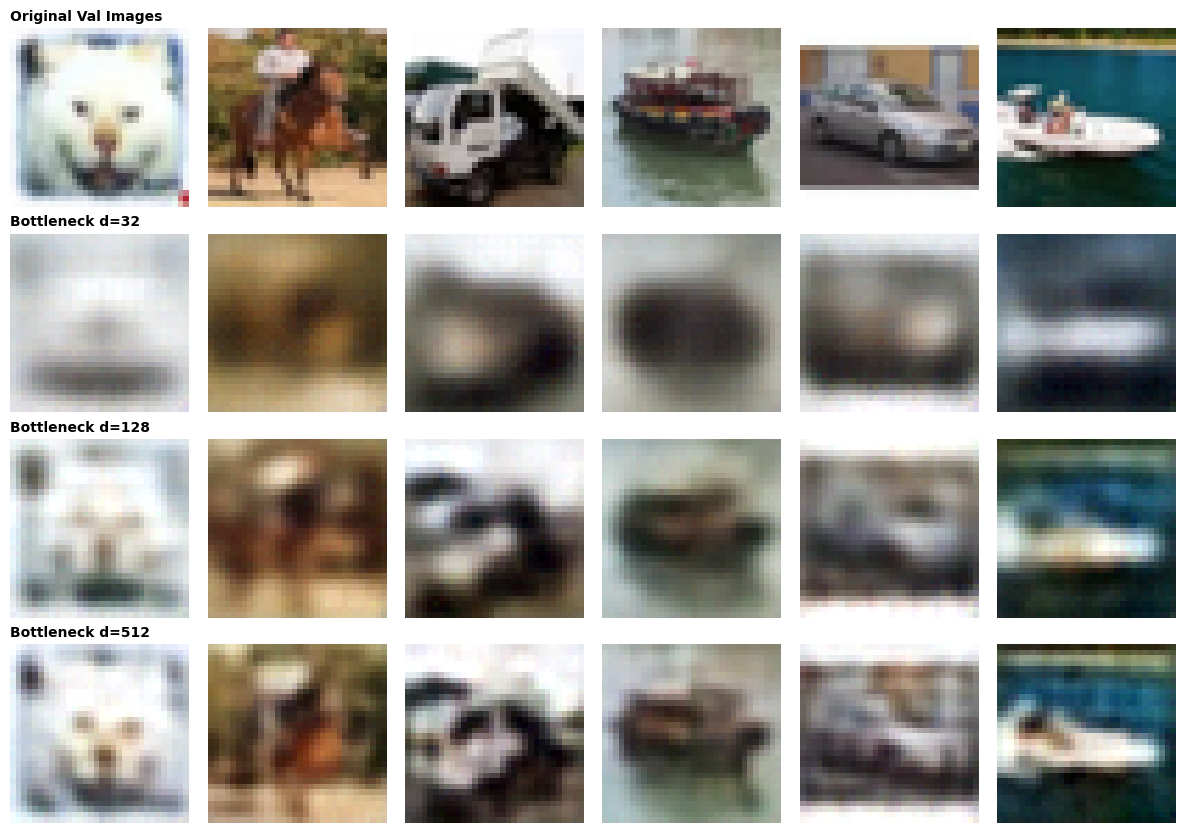

In [26]:
if __name__ == "__main__":
    SEED = 260007
    EPOCHS = 30
    LR = 1e-3
    WD = 1e-4
    BOTTLENECKS = [32, 128, 512]
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    logger.info(f"Running Question 3 Part (a) on device: {DEVICE}")

    train_loader, val_loader, test_loader, mean, std = get_cifar10_loaders(seed=SEED)

    results = []
    trained_models = {}

    for d in BOTTLENECKS:
        logger.info(f"\nTraining ConvAutoencoder with Bottleneck d = {d}...")
        set_global_seed(SEED)
        model = ConvAutoencoder(bottleneck_dim=d)
        params = count_parameters(model)

        model, best_val_mse = train_autoencoder(
            model, train_loader, val_loader, epochs=EPOCHS, lr=LR, weight_decay=WD, device=DEVICE
        )

        weight_path = f"cae_d{d}.pt"
        torch.save(model.state_dict(), weight_path)
        logger.info(f"  Saved weights to {weight_path}")

        results.append({"d": d, "params": params, "val_mse": best_val_mse})
        trained_models[d] = model

    best_entry = min(results, key=lambda r: r["val_mse"])
    selected_d = best_entry["d"]
    selected_model = trained_models[selected_d]

    torch.save(selected_model.state_dict(), "cae_selected_clean.pt")

    test_mse = evaluate_mse(selected_model, test_loader, DEVICE)

    logger.info("\n" + "=" * 68)
    logger.info("QUESTION 3 PART (a) DELIVERABLES SUMMARY")
    logger.info("=" * 68)
    logger.info(f"{'Bottleneck (d)':<15} | {'Trainable Params':>18} | {'Validation MSE':>16}")
    logger.info("-" * 68)
    for r in results:
        marker = "  <-- Selected" if r["d"] == selected_d else ""
        logger.info(f"d = {r['d']:<11d} | {r['params']:>18,d} | {r['val_mse']:>16.6f}{marker}")
    logger.info("-" * 68)
    logger.info(f"Selected Model (d = {selected_d}) Official Test Set MSE: {test_mse:.6f}")
    logger.info(f"Saved selected model weights to: cae_selected_clean.pt")
    logger.info("=" * 68)

    plot_reconstructions(trained_models, val_loader, mean, std, device=DEVICE)